<h1><center>Data science for Geographers</center></h1>

<h2><center>Practical 4 - Modelling with categorical and count data</center></h2>

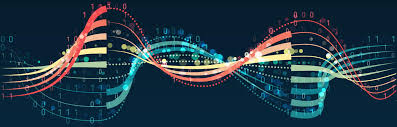

## Contents<a class="anchor" id="contents"></a>

- 1. [Introduction](#section1)
    - [Load the required packages](#section1.1)
    - [Load the data](#section1.2)
- 2. [Working with categorical predictor variables](#section2)
    - [The problem](#section2.1)
    - [Factor variable refresh](#section2.2)
    - [Dummy variables and selecting a reference category](#section2.3)
    - [Exercise](#exercise2)
- 3. [Working with categorical dependent variables?](#section3)
    - [Why is modelling categorical outcomes difficult?](#section3.2)
    - [Logistic regression](#section3.3)
    - [Interpretation: logit scale versus odds ratios](#section3.4)
    - [Model fit with logistic regression](#section3.5)
    - [Exercise](#exercise3)
- 4. [Working with count dependent variables](#section4)
    - [Why are counts difficult?](#section4.1)
    - [Poisson regression](#section4.2)
    - [Interpretation: rate ratios](#section4.3)
    - [A word of warning: overdispersion](#section4.4)
    - [Exercise](#exercise4)
- 5. [Conclusions](#section5)


## 1. Introduction<a class="anchor" id="section1"></a>

So far in the course, we have successfully managed to import our data, clean it and recode the necessary variables before finally running our first regression model. Initially we started with just a simple linear regression model. This simple analysis consisted of our dependent variable (the rates of smokers during pregnancy in datazones) predicted by a single independent variable (the density of tobacco retailers in those datazones). Because we know that smoking is predicted by other factors, some of which are also related to your likelihood of living in an area of higher density (i.e. levels of deprivation etc) we then estimated a more complex model where we add these other factors (known as confounders). In the previous practical we then started to look at the mechanics of linear regression and to understand some of the important assumptions we need to make in order to interpret the results.

Up to now, we have been working almost exclusively with continuous data and haven't given any consideration to how we might model categorical data. In this practical, we are going to cover how we go about modelling categorical data, both when we have predictor or independent variables that are categorical, but also when we have outcome or dependent data that is also categorical. The first of these is quite straightforward, but the second requires a different regression modelling approach known as logistic regression. Then, right at the end, we will have a brief look at a close cousin of logistic regression called Poisson regression, which is what we use when our outcome is a <b><i>count</b></i> of something (e.g. the number of smokers in a datazone).

Ok, so let's go through the usual initial steps.

### Load the required packages<a class="anchor" id="section1.1"></a>

First, let's load the packages that we will need.

In [ ]:
library(tidyverse)

### Load the data<a class="anchor" id="section1.2"></a>

Next let's load our data. This week we are using a slightly different file called `merged_data_counts.csv`. It is exactly the same as the `merged_data.csv` file you created in the first practical, but I have added two extra columns to it: `smokers` (the number of women in each datazone who were recorded as smokers during pregnancy) and `pregnant_women` (the total number of pregnant women in that datazone). These are the two numbers that the `smoking_rate` variable we have been using all along was calculated from. We won't need them until the final section so don't worry about them for now.

In [ ]:
analysis_data <- read_csv("merged_data_counts.csv")

In the last practical we removed a handful of datazones with extremely high numbers of tobacco retailers per 1000 people (more than 100). If you remember, these were tiny city-centre datazones with very few residents but lots of shops. Let's remove these again so that our results match what we did last week...

In [ ]:
#Remove the datazones with extreme retailer densities, as we did last week
analysis_data <- analysis_data %>%
    filter(retailers_adj <= 100)

[Back to contents](#contents)

Now let's move onto how we deal with predictor variables that are categorical.

## 2. Working with categorical PREDICTOR variables<a class="anchor" id="section2"></a>

The first step in any analysis involving categorical variables is to identify which of your variables of interest are actually categorical. By default, when R first imports data it treats most variables as numeric. We have seen in previous practicals how to identify the variable type of every variable in our data but also how to convert them into `factor` variables (what R calls categorical data). Most variables are obviously categorical, but in some cases it is not always obvious. For example, age on its own is often considered a continuous variable but in reality it has many characteristics that are more like a categorical variable. It has a pretty finite number of values (e.g. 0 to max 120!) for one thing! Many studies therefore create categorical versions of age (e.g. 26-30, 31-45 etc). As is always the case how you specify your variables depends on your research question and your underlying knowledge of the thing you are studying. 

So let's look at how we can use categorical information as a predictor variable.

The first thing we need to do is check the different types of each of our variables. Remember each variable that is a categorical variable needs to be recognised as a factor (or a `fct` type) by R.

We can do this with the `head` command but we can also use the `str()` command. This command is very helpful as it compactly displays the contents of our data object, including the type of each variable. Check the variable type for `simd_rank` and `simd_quintile`. You should see they are both type `dbl`, in other words numeric.

In [ ]:
head(analysis_data)
str(analysis_data)

### The problem<a class="anchor" id="section2.1"></a>

Before we actually change any of the categorical variables into factors, let's have a look at what happens in our regression if we just add them as standard numeric variables. This will hopefully illustrate why we need to use a special approach for them in our later models.

Below, we are running two models; the first is a standard model predicting `smoking_rate` on the basis of `simd_rank` which is a continuous measure (i.e. varies between 1 and 1,600, the total number of datazones in our simulated Scotland) showing datazones ranked by deprivation from most deprived (rank 1) to least deprived. The second model, is the same but instead is using the categorical version of SIMD `simd_quintile` which groups the `simd_rank` variable into 5 equal groups (in other words it varies between 1 and 5). This variable is categorical but for the purposes of illustration we have included it as continuous.

In [ ]:
#Run the standard regression once with continuous predictor and then with categorical predictor

continuous_predictor_regression <- lm(smoking_rate ~ simd_rank, data = analysis_data, na.action = na.exclude)
categorical_predictor_regression  <- lm(smoking_rate ~ simd_quintile, data = analysis_data, na.action = na.exclude)

summary(continuous_predictor_regression)
summary(categorical_predictor_regression)

Now look and compare the effect sizes across the models, they are both in the right direction and are negative i.e. as deprivation decreases, smoking rate also decreases. But the size of the effects is very different. The interpretation of both of these models as they stand is as follows:

- Model 1 (continuous), as deprivation rank increases by one (i.e. becomes less deprived) smoking rate decreases by <b><i>0.016 percentage points</b></i>
- In model 2 as simd quintile increases by one unit (i.e. becomes less deprived) smoking rate decreases by <b><i>5 percentage points</b></i>.

The reason for the massive difference in these effects is because the range of values in both is much different, and therefore the relevant change in the outcome from a <b><i>single</b></i> unit change in the predictor is very different as well.

Let's now look at the scatterplot of the these two regressions with a line of best fit added.

In [ ]:
##Show a standard scatterplot
ggplot(analysis_data, aes(x=simd_rank, y=smoking_rate)) +
  geom_point(size=2, shape=23)+
  geom_smooth(method=lm, se=FALSE)

##Show an attempt to show a scatterplot with categorical data
ggplot(analysis_data, aes(x=simd_quintile, y=smoking_rate)) +
  geom_point(size=2, shape=23)+
  geom_smooth(method=lm, se=FALSE)

Hopefully you can see that while it is theoretically possible to run a normal regression with categorical variables, the second model does not do a great job of capturing the underlying relationship. Clearly, it would make more sense to calculate the <b><i>mean</b></i> `smoking_rate` for <b><i>each level</b></I> of the  `simd_quintile` categorical variable. As we will see, this is essentially what R does automatically when adding a factor variable to your regression.

### Factor variable refresh<a class="anchor" id="section2.2"></a>

Ok, so let's now go on to do this properly. First, let's go ahead and create a factor variable version of the `simd_quintile` variable (remember it is currently a numeric variable!). Check the data afterwards to make sure it has been changed appropriately.

In [ ]:
#create and label a new categorical variable
analysis_data <- analysis_data %>% 
    mutate(simd_quintile = as.factor(simd_quintile)) %>% 
    mutate(simd_quintile = fct_recode(simd_quintile,
                                        "Most deprived" = "1", 
                                        "Second" = "2", 
                                        "Third" = "3", 
                                        "Fourth" = "4", 
                                        "Least deprived" = "5"))


#Note that the new variable has been changed to a "fct" and has been relabelled

head(analysis_data)
str(analysis_data)

When working with continuous variables, we tended to look at things like the mean, standard deviation and histograms to examine the distribution of the variable. With categorical data we tend to use tables a lot more.

The code below is how you would go about producing a table showing the numbers of observations in each `simd_quintile` category. It uses the `group_by` function and the `summarise` function to show us the total counts. The summarise function takes an argument `n=()`. The `n` is basically a function passed to the `summarise` command that says "sum the total number of observations specified in `group_by`".  

In [ ]:
#Now we have created our categorical variable we will want to look at a table of it

#Simple table
analysis_data %>%
  group_by(simd_quintile) %>%
  summarise(n = n())

We can also add some other useful columns of information to the table if we wish including for example the cumulative total, the percentage of the total in each group as well as finally the cumulative percentage. We do this using the `mutate` command followed by the calculations of each, these are:

- `cumsum()` - a function to calculate the cumulative total
- `round((n / sum(n)), 3)` - a calculation for the percentage rounded to 3 significant figures using the `round` function.
- `cumsum(freq = n / sum(n)), 3)` - the calculation of the cumulative percentage combining the various things above

In [ ]:
#Simple table with some additional summary information
analysis_data %>%
  group_by(simd_quintile) %>%
  summarise(n = n()) %>%
  mutate(
    CumulativeTotal = (cumsum(n)),
    percent = round((n / sum(n)), 3),
    cumuPer = round(cumsum(freq = n / sum(n)), 3))

### Dummy variables and selecting a reference category<a class="anchor" id="section2.3"></a>

Ok, now we have our correctly coded categorical variable as a factor. We are ready to run the regression. Because the variable is now a factor, all we have to do is add the variable in the usual way.

In [ ]:
##Now re-run our regression to use new variable
categorical_predictor_regression  <- lm(smoking_rate ~ simd_quintile, data = analysis_data, na.action = na.exclude)
summary(categorical_predictor_regression)

Look at this output. What do you notice is different about it?

We now have 4 coefficients or parameters, whereas before we had 1. Why?

This is because each coefficient now corresponds to each level of the variable. R has created for us automatically what are known as <b><i>dummy variables</b></i> or what can also be called <b><i>binary variables</b></i>. Dummy variables are variables that take on one of two values; 1 if the value is in the group and zero otherwise. So each level of `simd_quintile` is a dummy variable. If the dummy variable is for level 1, then the value will be 1 if the observation is in level 1 and zero otherwise. For the level 2 dummy variable, the values will be 1 if the observation is on level 2 and zero otherwise and so on.

You might be wondering why 4 and not 5 dummies are given (given the variable has five levels...)?

The reason is that because we are estimating what we call a <b><i>relative effect</b></i> here. It is relative because each coefficient is <b><i>relative</b></i> to level 1 of the categorical variable. So looking at the output above, the second quintile has smoking rates that are about 7.2 percentage points lower <i>on average</i> than rates in the first (most deprived) simd quintile. The least deprived quintile has smoking rates that are about 20.6 percentage points lower <i>on average</i> than the first level, and so on. In this case, level 1 is acting as what we call the <b><i>reference category</b></i>. Reference in the sense that it is the category to which all of the other categories are compared.

You might be wondering, "what if I wanted to change the reference category"? R by default will use the first category as the reference, but you can change this if you wish to using the `relevel()` function. This function allows you to specify a level you wish to use as the reference. Let's do this below, making the second level of `simd_quintile` the reference.

In [ ]:
categorical_predictor_regression  <- lm(smoking_rate ~ relevel(simd_quintile, ref = "Second"), data = analysis_data, na.action = na.exclude)
summary(categorical_predictor_regression)

You can see that now all of the groups are being compared to the second level. Notice that the differences between the groups haven't actually changed, we are just describing them from a different starting point (e.g. the most deprived quintile is now 7.2 percentage points <b>higher</b> than the second quintile, the mirror image of what we saw before).

If you want to see this for yourself, have a go with the <b>reference category explorer</b> (there's a link to it below). It lets you make any of the quintiles the reference category and shows you what changes in the model (and what doesn't!). It also shows you what happens if we treat the quintiles as numbers instead.

https://tc245.github.io/data-science-apps/reference/

Note: don't be confused by the output splitting the table onto a new line. The output looks confusing because the columns can't fit onto a single page so R has broken the output onto separate lines so that the t-statistic and p values are on a new line!

Of course you can also combine both categorical and continuous predictors in the same model. Let's do this by adding our retailer density variable to the same model we estimated above.

In [ ]:
categorical_predictor_regression  <- lm(smoking_rate ~ retailers_adj + simd_quintile, data = analysis_data, na.action = na.exclude)
summary(categorical_predictor_regression)

As you can see, the interpretation remains the same as before.

### Exercise <a class="anchor" id="exercise2"></a>

1. Produce a table summarising the numbers of datazones that are in different categories of urban and rural


2. Check the type of the existing urban and rural (`urban_rural`) variable and if neccessary convert it to a factor.


3. Run a regression model predicting smoking rates on the basis of the levels of the urban or rural variable.


4. Repeat the model above, but this time, use "Remote Rural" as the reference category and adjust for the level of deprivation and the retailer density in the datazone.

Enter your answers into the empty code cell below. Once you have had a go, the solutions are in the hidden cell underneath it: click on the three dots (`...`) to reveal the code. Make sure you run the solutions cell before moving on as some of the code later in the practical may rely on it!

In [ ]:
#Solutions
#1.Simple table with some additional summary information
analysis_data %>%
  group_by(urban_rural) %>%
  summarise(n = n()) %>%
  mutate(
    CumulativeTotal = (cumsum(n)),
    percent = round((n / sum(n)), 3),
    cumuPer = round(cumsum(freq = n / sum(n)), 3))

#Just the raw numbers
analysis_data %>%
  group_by(urban_rural) %>%
  summarise(n = n())

#2. Use the str() command to display the variable types
str(analysis_data)

#and convert the urban and rural variable to a factor, note no need to label as labels
analysis_data <- analysis_data %>%
    mutate(urban_rural = as.factor(urban_rural))

#3.
smoking_urban_rural  <- lm(smoking_rate ~ urban_rural,
                           data = analysis_data,
                           na.action = na.exclude)
summary(smoking_urban_rural)

#4.
smoking_urban_rural_dep  <- lm(smoking_rate ~ relevel(urban_rural, ref = "Remote Rural")
                           + simd_quintile
                           + retailers_adj,
                           data = analysis_data,
                           na.action = na.exclude)
summary(smoking_urban_rural_dep)

[Back to contents](#contents)

## 3. Working with categorical DEPENDENT variables<a class="anchor" id="section3"></a>

Ok, so we know how to deal with categorical <b><i>predictor</b></i> variables, but what about categorical <b><i>outcomes</b></i> (dependent variables)?

To illustrate, we are going to use a small subset of the data to make the plots that we are going to produce easier to read. We are going to focus on rural areas for this section, so restricting our analysis to the 375 rural datazones in our data only.

Let's start by creating an additional data object called `rural_only` which consists of just the rural datazones.

In [ ]:
rural_only <- analysis_data %>% 
    filter(urban_rural_2cat == "Rural")

And check we have only the rural datazones by creating a table from this new data object.

In [ ]:
#check we only have rural in this new data
rural_only %>%
  group_by(urban_rural_2cat) %>%
  summarise(n = n())

Next we have to create the variable that we want to predict. For the purposes of illustration we are going to create a binary categorical variable (i.e. one with only two levels) based on the original smoking rates variable. I have chosen an arbitrary cut-off of 20% to divide my categories. So we will be creating a variable that has the values "0" for areas with smoking rates below 20% and "1" for areas that have smoking rates of 20% or more. Keep in mind that for your own projects you will need to provide a good justification for any categorising decisions you make (based on your research question and the literature).

Note below that for the purposes of logistic regression, the variable <b><i>does not</b></i> have to be a factor type but it <b><i>does</b></i> have to be coded with only zeros and ones (so not e.g. "2" and "3") and it has to have <b><i>two and only two levels</b></i> (we will discuss the situation when we have more than two levels in our outcome variable at the end of the practical).

The code below does this for us and creates a new variable called `smoking_rate_binary`.

In [ ]:
rural_only <- rural_only %>% 
    mutate(smoking_rate_binary = as.numeric(smoking_rate >= 20))

Let's check this new variable to make sure it makes sense using a table as before.

In [ ]:
#Check this new variable
rural_only %>%
  group_by(smoking_rate_binary) %>%
  summarise(n = n())

Ok, now we have our variable.

In [ ]:
smoking_rural  <- lm(smoking_rate_binary ~ simd_rank, 
                           data = rural_only, 
                           na.action = na.exclude)

summary(smoking_rural)

### Why is modelling categorical outcomes difficult?<a class="anchor" id="section3.2"></a>

On the face of it, this regression model looks fine, but let's look at in more detail with a scatterplot.

In [ ]:
ggplot(rural_only, aes(x=simd_rank, y=smoking_rate_binary)) +
  geom_point(size=2, shape=23)+
  geom_smooth(method=lm, se=FALSE)

This is a problem. Clearly our standard linear regression model is not appropriate for this type of data. The modelled line does not accurately reflect the underlying data.

In [ ]:
ggplot(rural_only, aes(x=simd_rank, y=predict(smoking_rural))) +
  geom_point() +
  geom_hline(yintercept=0, colour='red') +
  labs(x='SIMD rank', y='Predicted Values', title='Predicted Values from our model')

When working with binary variables like this, what we are effectively doing is working with probabilities, in other words the <b><i>probability</b></i> of being in the "1" category. In some senses linear regression does provide us with a useful approach as it can simply predict the probability of being a "1" rather than the actual value. But, look at the plot above. The red line marks a predicted probability of zero and you can see that for the least deprived rural datazones the model is predicting probabilities that are less than zero (40 of them, in fact!), which is impossible. It could also predict values that are above 1 which is also a problem.

The reason this is the case is because the standard linear model <b><i>assumes</b></i> that the outcome varies around a straight line with <b><i>normally distributed</b></i> errors, which can take any value at all. A binary outcome doesn't behave like this. Probabilities are stuck between 0 and 1 and a binary variable follows a different distribution known as the <b>binomial</b> distribution.

You don't need to worry too much about what this means but the binomial distribution refers to the particular context of binary variables. It essentially describes the distribution of expected successes (i.e. the number of "1s" in our binary variable) in an experiment given a particular sample size and underlying probability. As an example, here is the distribution of expected numbers of tails if we were to flip a coin 100 times:

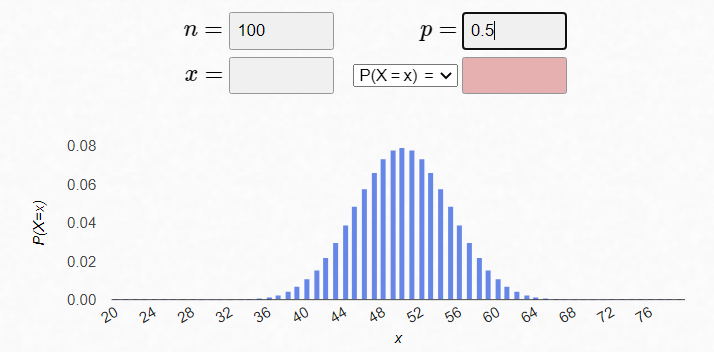

We know that the probability of a tails is 50/50 or 0.5 so if we flipped a coin 100 times the probability of say:

- 64 tails is very unlikely
- 36 tails is very unlikely
- 50 tails much more likely

Based on the above example, when tossing a coin 100 times, the probability that we would get exactly 64 tails is only 0.00156. In other words less than 1% (0.156%).

You can try out different binomial distributions at this link if you like! This is a helpful tool for visualising and understand probabilities.

https://tc245.github.io/data-science-apps/binomial/

Going back to our data, by using the binomial distribution (rather than the normal distribution) our predicted probabilities look like this instead:

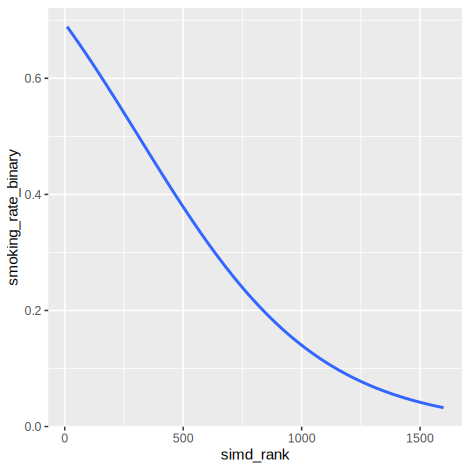

You can see that the fitted line is "flattened" at the ends ensuring that we only get predicted values on the interval 0-1. Incidentally, the curve in the image above has a special name, it is known as the <b><i>logistic curve</b></i>.

This is great, but has introduced another problem for us. Can you think what it is? Looking at this line, what do you see? Is it straight?

As you should remember from the previous practical, ordinary linear regression is not well equipped to handle non-straight lines. One of the key assumptions of ordinary linear regression is that the relationship between the predictor and outcome variables is linear. So, to model this data we need to extend the concept of regression a little further, and use a technique known as logistic regression (because it is based on predicting probabilities that follow a logistic curve!).

### Logistic regression<a class="anchor" id="section3.3"></a>

Logistic regression is part of a family of statistical models called generalised linear models (GLMs for short). They are generalised because they follow the same basic principles of regression but with some additional steps that allow us to relax the assumption of linearity. In the previous practical I mentioned that one approach to dealing with non-linear relationships is to adjust or transform the dependent variable in such a way that it behaves in a more linear fashion. This is the basis of how we use regression to model binary outcomes. We take the probabilities, carry out a mathematical transformation on them and model them in the same way as with ordinary regression.

In the case of logistic regression this involves:

- Converting the probabilities into odds (like in horse racing i.e. 2:1 or 10:1).
- Taking the natural logarithm of these odds (called the log odds or <b><i>logit</i></b>)
- Fitting a normal regression to this new transformed variable

Odds are calculated according to the following formula:

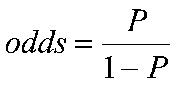

Where <b><i>p</B></I> is the probability. So a probability of 0.8 converts into odds of 4 (i.e. 0.8/(1-0.8) ). A bookmaker would refer to this as 4/1 on! A probability of 0.2 converts into odds of 0.25 (i.e. 0.2/(1-0.2) ). A bookmaker would refer to this as 4/1 against! 

The next step is to take the natural log of the odds. In the simplest terms, this removes the curve in the line. If we take the log of the examples above, we get log-odds or logit values of 1.39 and -1.39 respectively. As you can see, positive log odds are probabilities greater than evens (or 0.5) and negative log-odds are probabilities less than evens.  

The code below does these calculations for illustration.

In [ ]:
#first calculate the odds
0.8/(1-0.8)

#Then take the natural log of this number
log(4)

#We can combine all of this into one command
log(0.8/(1-0.8))

The really helpful thing here is that R does the transformations we did above automatically when running a logistic regression so we don't need to worry about doing these calculations ourselves. But the key to remember is that after the transformation, the models are fitted on the <b><i>new transformed variable</b></i>, i.e. the log-odds.

Let's run a logistic regression, generate some predicted values and see how they look.

The code below runs the logistic regression and then adds a column (`predicted_glm`) to the data object that is the predicted values from this model. It then generates a plot of the predicted values for the predictor variable `simd_rank`. 

Don't worry about the commands, we will look at that in more detail a little bit later on.

In [ ]:
glm_fit <- glm(smoking_rate_binary ~ simd_rank,
              data = rural_only,
              family = binomial(link='logit'),
              na.action = na.exclude)

rural_only <- rural_only %>% 
    mutate(predicted_glm = predict(glm_fit, type="link"))

ggplot(rural_only, aes(x=simd_rank, y=predicted_glm)) + 
    geom_point()

Remember these are predicted values based on our <b><i>transformed variable</i></b> which is on the log-odds scale. As you can see, the predicted values lie perfectly on a straight line so we have met our assumption of linearity. And because (unlike probabilities) the log-odds <b><i>can</b></i> take on values that are less than 0, that is not a problem here either!

However, because we have transformed the variable, the interpretation of these predicted values is not very intuitive (what does a value for log odds actually mean?!). But we can of course reverse the transformation to get back to the more intuitive probabilities as we do below, which gives us our nice logistic curve...

In [ ]:
ggplot(rural_only, aes(x=simd_rank, y=smoking_rate_binary)) +
  geom_smooth(method = "glm", 
    method.args = list(family = "binomial"), 
    se = FALSE) 

The key to remember here is that R does all of this for us in the `glm` model command. We just need to know roughly what is going to be able to interpret the results. 

Before we examine the actual model output, let's just go over the command that produced this output from earlier so we know what each part is doing. Here is the command again:

`glm_fit <- glm(smoking_rate_binary ~ simd_rank, data = rural_only, family = binomial(link='logit'), na.action = na.exclude)`
              
For the most part, the command is the same as the standard linear regression model. The only difference is we use the `glm` command (because we are using a "generalised linear model") instead of `lm` (which is just the "linear model"). We also have to specify the family of distributions that the model will use, in this case this is the "binomial" distribution as we discussed above and how this distribution links to our data. As we are using the log-odds or the logit we specify `logit` as the link.

So lets look at the actual model summary.


In [ ]:
summary(glm_fit)

The model can be interpreted in exactly the same way as a normal linear regression. The coefficient or estimate tells us the change in <b><i>log-odds</b></i> of the outcome given a 1 unit increase in SIMD rank. The only problem is that as we discussed before log-odds on their own are not very meaningful. Instead we need to convert them to what are called <b><i>odds ratios</b></i>.

### Interpretation: logit scale versus odds ratios<a class="anchor" id="section3.4"></a>

In the simplest terms, converting from log-odds/logits to odds ratios is a relatively simple process. All we need to do is exponentiate the coefficients from our models. We can do this using the `exp()` function. 

First we exponentiate the coefficients.

In [ ]:
exp(coef(glm_fit))

And then we do the same to the confidence intervals. 

In [ ]:
exp(confint(glm_fit))

The resulting odds ratios have a specific interpretation. An odds ratio greater than 1 tells us that there are <b><i>increased</b></i> odds of the outcome. In this case it would mean higher odds that an area has a smoking rate of 20% or more. The actual effect we observe is less than 1 (0.997) which means that as the SIMD rank increases (i.e. as deprivation reduces), the odds of an area having a smoking rate of 20% or more decrease. Odds ratios can also be interpreted as percentages. For example, an odds ratio of 1.5 would mean a 50% <b><i>increase</b></i> in the odds of the outcome. Similarly, an odds ratio of 0.75 would mean a 25% (i.e. 1-0.75) <b><i>decrease</b></i> in the odds. So our odds ratio of 0.997 means that the odds fall by about 0.3% for every one place increase in SIMD rank (that sounds small, but remember our ranks go all the way from 1 to 1,600!).

<b>NOTE: Be careful not to describe odds ratios as changes in the "risk" or probability of the outcome. Odds and probabilities are not the same thing (look back at the formula above). For example, if the probability of an outcome is 0.5, the odds are 1. Doubling the odds to 2 gives a probability of 0.67, not 1! So an odds ratio of 2 does not mean "twice as likely".</b>

The confidence intervals have the same interpretation as usual i.e. the interval within which we are 95% confident the true value of the odds ratio lies. If the interval <b><i>does not</b></i> include one (which is the value of an odds ratio when there is no difference in the odds), it is statistically significant (i.e. there is some difference in the odds) which will be mirrored in the full regression summary output as well (i.e. in terms of the p-value and the significance).

If you want to see how probabilities, odds and log-odds fit together, have a go with the <b>logistic regression explorer</b> (there's a link to it below). It shows our model on all three scales, turns the coefficient into odds ratios for you, and lets you see what happens if we move our 20% cut-off.

https://tc245.github.io/data-science-apps/logistic/

### Model fit with logistic regression<a class="anchor" id="section3.5"></a>

Unfortunately, the standard model fit tools like R-squared, multiple R-squared and adjusted R-squared do not apply to logistic regression. Instead we have to rely on the AIC which we covered in the last practical.

Let's look at the model output again:

In [ ]:
summary(glm_fit)

You can see at the bottom that the AIC has been included automatically. If we were to run another model with an additional variable, we should see a reduction in the AIC and therefore an improvement in the fit of the model. Let's try this by adding the `retailer_adj` variable:

In [ ]:
glm_fit <- glm(smoking_rate_binary ~ simd_rank + retailers_adj,
              data = rural_only,
              family = binomial(link='logit'),
              na.action = na.exclude)

summary(glm_fit)

As you can see this results in a slight improvement in the model. Lets try adding simd as a categorical variable and see what difference this makes.

In [ ]:
glm_fit <- glm(smoking_rate_binary ~ simd_quintile + retailers_adj,
              data = rural_only,
              family = binomial(link='logit'),
              na.action = na.exclude)

summary(glm_fit)

Looking at the AIC, this doesn't seem to have improved the model. 

Remember here, the interpretation of the coefficients when using categorical predictors is also in reference to the specified level, in this case the most deprived. Let's go ahead and calculate the odds ratios.

In [ ]:
exp(coef(glm_fit))
exp(confint(glm_fit))

Looking at these odds ratios, the odds ratios for the SIMD quintiles are all below 1 indicating that compared to the most deprived areas, all other SIMD quintiles have much lower odds of having a smoking rate of 20% or more. For the least deprived quintile, there is about a 97% reduction (i.e. 1-0.029) in the odds of a smoking rate of 20% or more.

### Exercise<a class="anchor" id="exercise3"></a>

1. Calculate the log odds for a probability of 0.6. Experiment with some other probabilities if you like, especially ones above and below 0.5!


2. Conduct a logistic regression predicting whether a datazone has a smoking rate of 20% or more for <b><i>just the urban datazones</i></b> based on the density of tobacco retailers. Make sure you can interpret the output including calculating the relevant odds ratios. Note: you may need to create some of these variables and/or make sure they are factor variables where relevant.


3. Repeat the above but additionally adjust this model for SIMD quintile deprivation.


4. Compare the AIC values, which is the better fitting model?

Enter your answers into the empty code cell below. Once you have had a go, the solutions are in the hidden cell underneath it: click on the three dots (`...`) to reveal the code. Make sure you run the solutions cell before moving on as some of the code later in the practical may rely on it!

In [ ]:
#code solutions
#1.
log(0.6/(1-0.6))

#2.
#Create the urban only subset of data
urban_only <- analysis_data %>%
    filter(urban_rural_2cat == "Urban")

#Add a binary smoking variable (areas with smoking rates of 20% or more)
urban_only <- urban_only %>%
    mutate(smoking_rate_binary = as.numeric(smoking_rate >= 20))

#run the model
urban_model_retailers <- glm(smoking_rate_binary ~ retailers_adj,
              data = urban_only,
              family = binomial(link='logit'),
              na.action = na.exclude)

#Calculate the odds ratios
exp(coef(urban_model_retailers))
exp(confint(urban_model_retailers))

#3.
urban_model_retailers_simd <- glm(smoking_rate_binary ~ retailers_adj + simd_quintile,
              data = urban_only,
              family = binomial(link='logit'),
              na.action = na.exclude)

exp(coef(urban_model_retailers_simd))
exp(confint(urban_model_retailers_simd))

#4.

summary(urban_model_retailers)
summary(urban_model_retailers_simd)

#The second model is clearly the better fitting model (it has a much lower AIC).

[Back to contents](#contents)

## 4. Working with COUNT dependent variables<a class="anchor" id="section4"></a>

<b>NOTE: This final section is a short introduction to one more type of model. If we run out of time in class, work through it in your own time. It is well worth doing if the outcome you are planning to use in your own project is a count of something!</b>

Ok, so I have a confession to make. In the last section we took a perfectly good continuous variable (the smoking rate) and chopped it into two groups using a cut-off of 20% that I more or less plucked out of the air. That was fine for the purposes of illustrating logistic regression but it is a bit wasteful. A datazone with a smoking rate of 19% and one with a rate of 2% end up in the same group, even though they are clearly very different places.

There is another way to think about our outcome though. Where does the smoking rate actually come from? It is just the <b><i>number</b></i> of pregnant women who smoke divided by the <b><i>total number</b></i> of pregnant women in the datazone (multiplied by 100 to make it a percentage). In other words, underneath our rate there is a <b><i>count</b></i>. A lot of the data that geographers work with looks like this: the number of crimes in a neighbourhood, the number of road traffic accidents at a junction, the number of hospital admissions in a datazone, the number of pubs on a high street and so on.

The two extra columns in this week's data (`smokers` and `pregnant_women`) give us these counts. Let's have a look at them alongside the smoking rate. We are back to using all of the datazones for this section, not just the rural ones.

In [ ]:
analysis_data %>%
    select(datazone, smokers, pregnant_women, smoking_rate) %>%
    head()

You can check for yourself that the smoking rate is just one divided by the other. For the first datazone, 2 smokers out of 23 pregnant women is 8.7%.

In [ ]:
2/23*100

### Why are counts difficult?<a class="anchor" id="section4.1"></a>

Just like we did with the binary variable, let's start by looking at what this variable looks like. The code below produces a bar chart showing how many datazones have 0 smokers, 1 smoker, 2 smokers and so on.

In [ ]:
ggplot(analysis_data, aes(x=smokers)) +
  geom_bar() +
  labs(x='Number of smokers', y='Number of datazones')

There are a few things to notice here, and they are true of pretty much all count data:

- Counts are always whole numbers. You can't have 2.4 smokers.
- Counts can never be less than zero.
- Most datazones are bunched up at the low end, with a long tail of datazones off to the right with much higher numbers. This is the skewed shape we met back in the earlier practicals.

Just as with the binary variable, this is a problem for ordinary linear regression. Remember, the standard linear model assumes that the outcome varies around a straight line with normally distributed errors, which can take any value at all, including fractions and negative numbers. Counts don't behave like that. Instead they tend to follow another distribution called the <b>Poisson</b> distribution (named after a French mathematician, and pronounced roughly "pwah-son"). The Poisson distribution describes how many times something happens when each individual occurrence is fairly rare. The classic example is the number of goals scored in a football match: most matches have 0, 1, 2 or 3 goals, a few have 5 or 6, and very occasionally you get a 9-0!

There is also a second problem that is specific to counts. Have a look back at the table above. A datazone with 4 smokers might sound like it has more of a smoking problem than one with 2, but that entirely depends on how many pregnant women live there. 4 smokers out of 40 women is a rate of 10%. 4 smokers out of 10 women is a rate of 40%! A count on its own doesn't tell us very much unless we also know how many people <i>could</i> have been counted. We call this number the <b><i>denominator</b></i> (it is the bottom half of the fraction when we calculate a rate). This is exactly the same reason we converted the number of tobacco retailers into retailers per 1000 people all the way back in the first practical.

So we need a model that can cope with whole numbers that can't go below zero, and that takes into account the number of pregnant women in each datazone. This is what Poisson regression does.

### Poisson regression<a class="anchor" id="section4.2"></a>

The good news is that you already know most of what you need to know. Poisson regression is another member of the family of generalised linear models (GLMs), just like logistic regression. So it follows exactly the same recipe: we transform the outcome so that it behaves in a more linear fashion and then fit a normal regression to the transformed variable.

In fact the transformation is simpler than for logistic regression. There is no need to convert anything into odds first. For Poisson regression we simply:

- Take the natural logarithm of the count
- Fit a normal regression to this new transformed variable

As before, R does all of this for us in the `glm` command. Let's run a Poisson regression predicting the number of smokers in each datazone using `simd_rank`.

In [ ]:
poisson_fit <- glm(smokers ~ simd_rank + offset(log(pregnant_women)),
              data = analysis_data,
              family = poisson(link='log'),
              na.action = na.exclude)

summary(poisson_fit)

Let's go over the command so we know what each part is doing. Compared with the logistic regression command from earlier there are only two differences:

- The family is now `poisson` instead of `binomial` and, because we are modelling the log of the count rather than the log-odds, the link is `log` instead of `logit`.


- There is an extra term in the model: `offset(log(pregnant_women))`. This is how we tell R about the denominator. An <b><i>offset</b></i> is not a predictor variable (you will notice that it doesn't get a coefficient in the output above). It just tells the model how many pregnant women there are in each datazone so that it compares like with like. It has to be logged because the model itself is working on the log scale. The effect of including it is that we are no longer modelling the <b><i>number</b></i> of smokers but the <b><i>rate</b></i> of smoking, which is what we are actually interested in.

The model output can be read in exactly the same way as before. The coefficient or estimate tells us the change in the <b><i>log</b></i> of the smoking rate given a 1 unit increase in SIMD rank. It is negative, so as the SIMD rank increases (i.e. as deprivation reduces) smoking rates go down, which is what we have found all along. But, just like the log-odds, a change on the log scale is not very meaningful on its own...

### Interpretation: rate ratios<a class="anchor" id="section4.3"></a>

...so we do exactly what we did with the logistic regression and exponentiate the coefficients and their confidence intervals using the `exp()` function.

In [ ]:
exp(coef(poisson_fit))
exp(confint(poisson_fit))

This time the result is not an odds ratio but a <b><i>rate ratio</b></i>. The rules are the same as for odds ratios. A rate ratio greater than 1 means a <b><i>higher</b></i> rate of the outcome, a rate ratio below 1 means a <b><i>lower</b></i> rate and a rate ratio of exactly 1 means no difference at all. They can also be read as percentages in the same way. Our rate ratio of 0.9989 means that the smoking rate falls by about 0.1% (i.e. 1-0.9989) for every one place increase in SIMD rank. Careful here: this is a <i>relative</i> change, so the rate is multiplied by 0.9989 for each place. It does not mean the smoking rate drops by 0.1 percentage points. As with the odds ratio earlier, this looks tiny but our ranks go all the way from 1 to 1,600. The confidence interval does not include 1, so the effect is statistically significant.

The big advantage of rate ratios over odds ratios is that they are much more intuitive. Remember the warning from earlier that you shouldn't describe an odds ratio of 2 as "twice as likely"? Well, a rate ratio of 2 really does mean "twice the rate". Nothing more complicated than that!

Ok, so let's fit a more interesting model. As with the logistic regression we will swap to using SIMD as a categorical variable and add in our tobacco retailer density variable `retailers_adj`.

In [ ]:
poisson_fit <- glm(smokers ~ simd_quintile + retailers_adj + offset(log(pregnant_women)),
              data = analysis_data,
              family = poisson(link='log'),
              na.action = na.exclude)

summary(poisson_fit)

Just like logistic regression, we can't use R-squared here and have to rely on the AIC, which you can see at the bottom of the output. It is lower than in the first model (6442 compared with 6482) so this is the better fitting of the two.

Now let's calculate the rate ratios.

In [ ]:
exp(coef(poisson_fit))
exp(confint(poisson_fit))

Remember that the interpretation of the SIMD quintiles is in reference to the most deprived quintile. The rate ratios get steadily smaller as we move through the quintiles. For the least deprived quintile the rate ratio is 0.26, so the smoking rate in the least deprived areas is about a quarter of the rate in the most deprived areas (a 74% reduction, i.e. 1-0.26) after taking retailer density into account.

The rate ratio for `retailers_adj` is 1.06. So for every additional tobacco retailer per 1000 people, the smoking rate is about 6% higher, after adjusting for deprivation. The confidence interval (1.05 to 1.07) does not include 1, so this is statistically significant.

Compare this with what we got from the logistic regression. There we could only say something about the odds of a datazone being above or below an arbitrary 20% cut-off. Here we have used all of the information in the data and can make a much more direct statement about smoking rates themselves.

### A word of warning: overdispersion<a class="anchor" id="section4.4"></a>

There is one important catch with Poisson regression that you need to know about. The Poisson distribution makes quite a strict assumption, which is that the variance of the counts is equal to their mean. Real data are often more spread out than this, which is known as <b><i>overdispersion</b></i>. When this happens the model still gives you sensible rate ratios, but the standard errors are too small, which means the confidence intervals are too narrow and the p-values are too optimistic.

There is a quick rule of thumb for checking this. Look at the bottom of the model summary above and find the line that starts `Residual deviance`. Divide the residual deviance by its degrees of freedom. If the answer is close to 1 you are fine. If it is a lot bigger than 1 (say above 2) you have a problem. For our model this is 2029 divided by 1571 which is about 1.3, so nothing much to worry about here.

If you do find overdispersion in your own project, the simplest fix is to change `family = poisson(link='log')` to `family = quasipoisson(link='log')` in the command. The rate ratios stay exactly the same but the standard errors are widened to account for the extra spread. There is also an alternative model called <b><i>negative binomial</b></i> regression that is often used for overdispersed counts, but that is beyond what we need for this course. If you think you might need it, come and ask me!

### Exercise<a class="anchor" id="exercise4"></a>

1. Conduct a Poisson regression predicting the number of smokers in <b><i>just the urban datazones</i></b> based on the density of tobacco retailers. Don't forget the offset! Make sure you can interpret the output including calculating the relevant rate ratios.


2. Repeat the above but additionally adjust this model for SIMD quintile deprivation. What happens to the rate ratio for tobacco retailer density? Why do you think this is?


3. Compare the AIC values, which is the better fitting model?


4. Check the better fitting model for overdispersion.

Enter your answers into the empty code cell below. Once you have had a go, the solutions are in the hidden cell underneath it: click on the three dots (`...`) to reveal the code.

In [ ]:
#code solutions
#1.
#Create the urban only subset of data
urban_only <- analysis_data %>%
    filter(urban_rural_2cat == "Urban")

#run the model
urban_poisson_retailers <- glm(smokers ~ retailers_adj + offset(log(pregnant_women)),
              data = urban_only,
              family = poisson(link='log'),
              na.action = na.exclude)

#Calculate the rate ratios
exp(coef(urban_poisson_retailers))
exp(confint(urban_poisson_retailers))

#2.
urban_poisson_retailers_simd <- glm(smokers ~ retailers_adj + simd_quintile + offset(log(pregnant_women)),
              data = urban_only,
              family = poisson(link='log'),
              na.action = na.exclude)

exp(coef(urban_poisson_retailers_simd))
exp(confint(urban_poisson_retailers_simd))

#The rate ratio for retailer density drops from about 1.14 to about 1.06. Deprived areas have both more
#retailers and more smoking, so some of the apparent effect of retailers was really down to deprivation.
#This is the confounding we talked about in Practical 2.

#3.
summary(urban_poisson_retailers)
summary(urban_poisson_retailers_simd)

#The second model is clearly the better fitting model (it has a much lower AIC).

#4.
#Residual deviance divided by its degrees of freedom. About 1.3, so not a problem.
deviance(urban_poisson_retailers_simd)/df.residual(urban_poisson_retailers_simd)

[Back to contents](#contents)

## Conclusion<a class="anchor" id="section5"></a>

We have covered a lot today! But you should now be equipped to carry out modelling on continuous, categorical and count outcome variables and also be able to use both types of variables as predictors.

One thing we haven't discussed today is the situation where we have a categorical outcome variable with <b><i>more</b></i> than two levels. Let's say for example, that we wanted to predict whether an area was in one of five groups of retailer densities (i.e. a variable similar to the `simd_quintile` but for tobacco retailer density). If we wanted to predict this, we couldnt use logistic regression as this will only work for variables with two categories. Unfortunately, this is very difficult to do. There is an approach known as <b><i>multinomial</b></i> regression modelling which can do this but it is an advanced technique and not widely used because it is very difficult to interpret. Instead, the most common thing to do is recode that variable into a binary selecting an appropriate grouping strategy based on a combination of existing literature (so that your work is comparable to existing studies) but also your specific research question.  

The final thing to note is that model diagnostics are much less straightforward when using logistic regression. With ordinary linear modelling, we can use the various plots we covered in the last practical. But equivalents for logistic regression are not as easy to come by (and the same goes for Poisson regression). However, as we covered, it is ok to use the AIC as a measure of fit.

[Back to contents](#contents)